# Chroma · Monday: a convolutional autoencoder for places

**Team 8 · AI Methods hackathon, IAAC MaAI 2026**

**Use case.** A user takes a photo of a place. The app finds the scenes that look most like it and turns their
place, time of day, season and colours into sound and music. The autoencoder gives each photo a short code
(its *latent vector*); photos with close codes look alike. We use it for **similarity search**.

**Data.** Places365 validation set (Zhou et al., 2017; non-commercial research and teaching; photos belong to
their owners, not republished): **36,500 photos of 365 scene types**, reduced to 64 × 64 px. The model trains on all of
them. Our six places (market, street, beach, mountains, metro, airport) are a labelled subset of 900, filtered to
731 scenes without close-ups, with time of day, season and colour labels (see `data_prep/`).

**Plan.** 1 · load and split first · 2 · three setups on the same split and seed · 3 · one table and a conclusion ·
4 · similarity search with a figure that proves it works · 5 · ONNX export and check.

## 0. Setup

In [1]:
import json, tarfile, time
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image

SEED = 8
SIZE = 64
torch.manual_seed(SEED); np.random.seed(SEED)

ROOT = Path("..")                       # notebook/ -> 01_autoencoder/
DATA, FIG, MODELS, APP = ROOT / "data", ROOT / "figures", ROOT / "models", ROOT / "model_app"
for d in (FIG, MODELS, APP):
    d.mkdir(exist_ok=True)
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.15.0+cpu | threads 4


## 1. The data

All 36,500 validation photos are read from the Places365 archive once, resized to 64 × 64 and cached as
`data/places64.npz` (pixels 0–255). The labels of our six places come from the `data_prep/` scripts.

In [2]:
CACHE = DATA / "places64.npz"
if not CACHE.exists():
    with tarfile.open(DATA / "raw" / "filelist_places365-standard.tar") as t:
        read = lambda s: t.extractfile(next(m for m in t.getmembers() if m.name.endswith(s))).read().decode().split("\n")
        cats = [l.split()[0] for l in read("categories_places365.txt") if l]
        val = dict(l.split() for l in read("places365_val.txt") if l)
    names, imgs, ys = [], [], []
    with tarfile.open(DATA / "raw" / "val_256.tar") as t:
        for m in t:
            n = Path(m.name).name
            if n in val:
                img = Image.open(BytesIO(t.extractfile(m).read())).convert("RGB").resize((SIZE, SIZE), Image.Resampling.BILINEAR)
                imgs.append(np.asarray(img)); names.append(n); ys.append(int(val[n]))
    np.savez_compressed(CACHE, x=np.stack(imgs), name=np.array(names), y=np.array(ys), cats=np.array(cats))

z = np.load(CACHE)
X_all, NAMES, Y_all, CATS = z["x"], z["name"], z["y"], z["cats"]
print(X_all.shape, X_all.dtype, "|", len(CATS), "scene types")

(36500, 64, 64, 3) uint8 | 365 scene types


### Split first

Before anything else: 80 % train, 10 % validation, 10 % test, random with a fixed seed. Every setup uses this split.

In [3]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(X_all))
n_tr, n_va = int(0.8 * len(perm)), int(0.1 * len(perm))
idx = {"train": perm[:n_tr], "val": perm[n_tr:n_tr + n_va], "test": perm[n_tr + n_va:]}
split_of = np.empty(len(X_all), dtype=object)
for k, v in idx.items():
    split_of[v] = k
print({k: len(v) for k, v in idx.items()})

to_tensor = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).float() / 255.0     # (N, 3, 64, 64), 0-1
Xtr, Xva, Xte = (to_tensor(X_all[idx[k]]) for k in ("train", "val", "test"))

{'train': 29200, 'val': 3650, 'test': 3650}


In [4]:
# Our six places, with the labels from data_prep/ (time, season, close-up filter, colours).
lab = pd.read_csv(DATA / "labels_auto.csv")
lab = lab.merge(pd.read_csv(DATA / "closeups.csv")[["file", "keep", "reason"]].rename(columns={"keep": "scene"}), on="file", how="left")
lab = lab.merge(pd.read_csv(DATA / "palette.csv"), on="file", how="left")
lab["name"] = lab["file"].str.split("/").str[-1]
pos = {n: i for i, n in enumerate(NAMES)}
lab["i"] = lab["name"].map(pos)
lab["split"] = split_of[lab["i"]]
lib = lab[lab["scene"] == 1].reset_index(drop=True)          # the 731 scenes the app searches
print(len(lab), "labelled photos,", len(lib), "kept as scenes")
print(pd.crosstab(lib["place"], lib["split"]))

900 labelled photos, 731 kept as scenes
split      test  train  val
place                      
airport      10     70    7
beach        10     74    4
market       19     93   19
metro         8     66   10
mountains    27    223   22
street        5     55    9


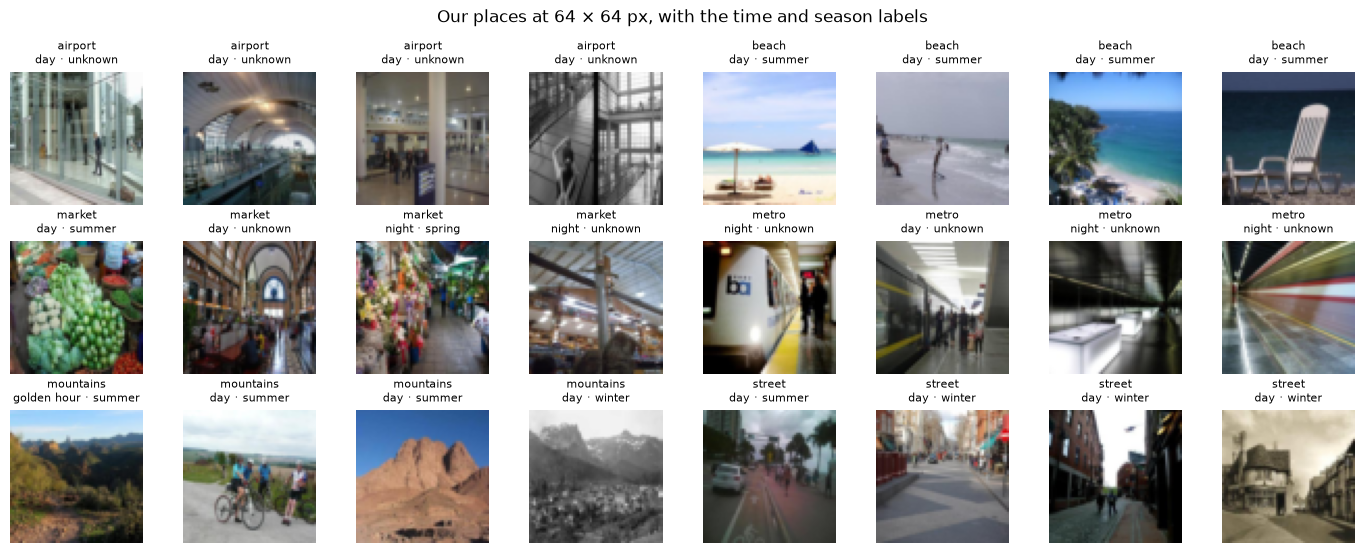

In [5]:
fig, axs = plt.subplots(3, 8, figsize=(14, 5.6))
for ax, (_, r) in zip(axs.flat, lib.groupby("place").sample(4, random_state=SEED).iterrows()):
    ax.imshow(X_all[r["i"]]); ax.set_title(f"{r['place']}\n{r['time']} · {r['season']}", fontsize=8); ax.axis("off")
plt.suptitle("Our places at 64 × 64 px, with the time and season labels"); plt.tight_layout()
plt.savefig(FIG / "01_samples.png", dpi=110); plt.show()

## 2. Three setups

| Setup | Encoder | Latent size | Why |
|---|---|---|---|
| A · dense-64 | flatten → 512 → 64 | 64 | the baseline from class |
| B · conv-64 | 4 conv layers (stride 2) | 64 | convolutions see neighbouring pixels: shapes, horizons, textures |
| C · conv-256 | same | 256 | a larger code keeps more detail, but is it a better *map*? |

Loss: mean squared error between input and reconstruction. Adam, learning rate 1e-3, batch 128, 12 epochs.

In [6]:
class DenseAE(nn.Module):
    def __init__(self, latent=64):
        super().__init__()
        d = 3 * SIZE * SIZE
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(d, 512), nn.ReLU(), nn.Linear(512, latent))
        self.dec = nn.Sequential(nn.Linear(latent, 512), nn.ReLU(), nn.Linear(512, d), nn.Sigmoid())
    def encode(self, x): return self.enc(x)
    def forward(self, x): return self.dec(self.enc(x)).view(-1, 3, SIZE, SIZE)


class ConvAE(nn.Module):
    def __init__(self, latent=64):
        super().__init__()
        ch = [3, 32, 64, 128, 256]
        enc = []
        for a, b in zip(ch[:-1], ch[1:]):                       # 64 -> 32 -> 16 -> 8 -> 4
            enc += [nn.Conv2d(a, b, 4, stride=2, padding=1), nn.BatchNorm2d(b), nn.LeakyReLU(0.1)]
        self.enc = nn.Sequential(*enc, nn.Flatten(), nn.Linear(256 * 4 * 4, latent))
        dec = []
        for a, b in zip(ch[::-1][:-2], ch[::-1][1:-1]):          # 4 -> 8 -> 16 -> 32
            dec += [nn.ConvTranspose2d(a, b, 4, stride=2, padding=1), nn.BatchNorm2d(b), nn.LeakyReLU(0.1)]
        self.fc = nn.Linear(latent, 256 * 4 * 4)
        self.dec = nn.Sequential(*dec, nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1), nn.Sigmoid())
    def encode(self, x): return self.enc(x)
    def forward(self, x): return self.dec(self.fc(self.enc(x)).view(-1, 256, 4, 4))


def mse(model, X, bs=512):
    model.eval(); tot = 0.0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = X[i:i + bs]; tot += ((model(xb) - xb) ** 2).mean().item() * len(xb)
    return tot / len(X)


LOG = MODELS / "training_log.txt"

def log(msg):
    print(msg, flush=True)
    with open(LOG, "a", encoding="utf-8") as f: print(msg, file=f)


def train(model, epochs=12, bs=128, lr=1e-3):
    torch.manual_seed(SEED)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        model.train(); g = torch.Generator().manual_seed(SEED + ep)
        order = torch.randperm(len(Xtr), generator=g); tot = 0.0
        for i in range(0, len(Xtr), bs):
            xb = Xtr[order[i:i + bs]]
            loss = ((model(xb) - xb) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(xb)
        hist.append((tot / len(Xtr), mse(model, Xva)))
        log(f"  epoch {ep + 1:2d}  train {hist[-1][0]:.5f}  val {hist[-1][1]:.5f}  ({time.time() - t0:.0f} s)")
    return hist, time.time() - t0

In [7]:
setups = {"A · dense-64": lambda: DenseAE(64), "B · conv-64": lambda: ConvAE(64), "C · conv-256": lambda: ConvAE(256)}
models, hists, rows = {}, {}, []
for name, make in setups.items():
    ckpt = MODELS / f"{name.split(' · ')[1]}.pt"           # weights are saved, so a rerun skips training
    torch.manual_seed(SEED); m = make()
    if ckpt.exists():
        saved = torch.load(ckpt, weights_only=False)
        m.load_state_dict(saved["state"]); hists[name], secs = saved["hist"], saved["secs"]
        log(f"{name}: loaded {ckpt.name}")
    else:
        log(name)
        hists[name], secs = train(m)
        torch.save({"state": m.state_dict(), "hist": hists[name], "secs": secs}, ckpt)
    m.eval()
    models[name] = m
    rows.append({"setup": name, "parameters": sum(p.numel() for p in m.parameters()),
                 "train time (min)": round(secs / 60, 1),
                 "val MSE": round(mse(m, Xva), 5), "test MSE": round(mse(m, Xte), 5)})

A · dense-64


  epoch  1  train 0.03726  val 0.02617  (30 s)


  epoch  2  train 0.02494  val 0.02349  (60 s)


  epoch  3  train 0.02311  val 0.02240  (93 s)


  epoch  4  train 0.02193  val 0.02159  (129 s)


  epoch  5  train 0.02104  val 0.02101  (174 s)


... (29 outputs left out)

  epoch  9  train 0.00785  val 0.00767  (994 s)


  epoch 10  train 0.00752  val 0.00750  (1094 s)


  epoch 11  train 0.00730  val 0.00728  (1198 s)


  epoch 12  train 0.00707  val 0.00793  (1305 s)


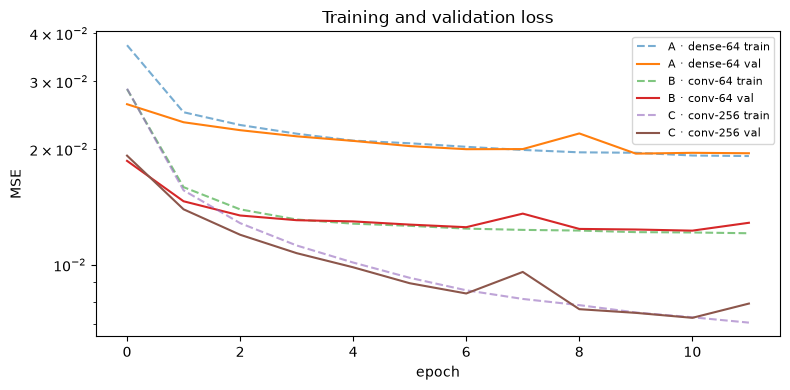

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, h in hists.items():
    ax.plot([a for a, b in h], "--", alpha=.6, label=f"{name} train"); ax.plot([b for a, b in h], label=f"{name} val")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.set_yscale("log"); ax.legend(fontsize=8); ax.set_title("Training and validation loss")
plt.tight_layout(); plt.savefig(FIG / "02_loss_curves.png", dpi=110); plt.show()

## 3. Comparison

In [9]:
table = pd.DataFrame(rows)
table.to_csv(FIG / "setups.csv", index=False)
table

,setup,parameters,train time (min),val MSE,test MSE
0,A · dense-64,12661824,7.0,0.01951,0.01930
1,B · conv-64,1909891,20.4,0.01286,0.01265
2,C · conv-256,3482947,21.8,0.00793,0.00779


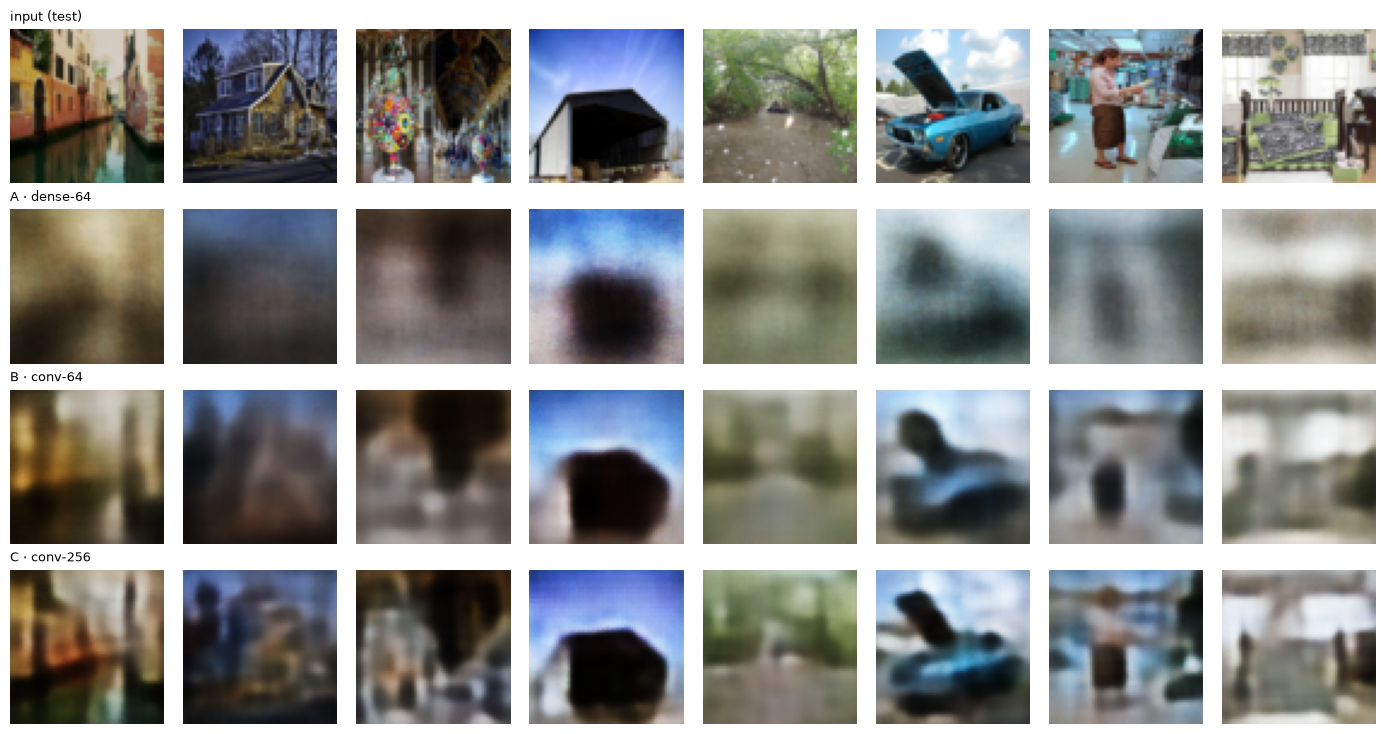

In [10]:
show = Xte[:8]
fig, axs = plt.subplots(4, 8, figsize=(14, 7.4))
for j in range(8):
    axs[0, j].imshow(show[j].permute(1, 2, 0)); axs[0, j].axis("off")
for i, (name, m) in enumerate(models.items(), 1):
    m.eval()
    with torch.no_grad(): rec = m(show)
    for j in range(8):
        axs[i, j].imshow(rec[j].permute(1, 2, 0).clamp(0, 1)); axs[i, j].axis("off")
    axs[i, 0].set_title(name, fontsize=9, loc="left")
axs[0, 0].set_title("input (test)", fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(FIG / "03_reconstructions.png", dpi=110); plt.show()

**What we conclude.**
- **Convolutions win.** With 7 × fewer parameters than the dense model, conv-64 reconstructs a third better (test MSE 0.0127 vs 0.0193). The dense model keeps blurry colour fields; the convolutional ones keep horizons, edges and textures.
- **A bigger code reconstructs better** (conv-256: 0.0078), but section 4 shows it does **not** search better. The extra numbers store detail that does not decide what kind of place it is.
- Validation loss goes down with the training loss for all three setups (figure 2): no overfitting in 12 epochs.

## 4. The use: similarity search

Each scene in our library of 731 gets its latent vector. For a query photo we return the closest vectors
(cosine similarity). **Proof that it works:** for test photos of our six places, we measure how often the 5
nearest scenes are the same *place*, and compare with chance. The autoencoder never saw a place label, so any
gain over chance comes from what it learned about how places look.

In [11]:
def embed(model, X, bs=512):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs): out.append(model.encode(X[i:i + bs]))
    z = torch.cat(out)
    return (z / z.norm(dim=1, keepdim=True)).numpy()

X_lib = to_tensor(X_all[lib["i"].to_numpy()])
queries = lib.index[lib["split"] == "test"].to_numpy()
chance = np.mean([(lib["place"] == p).mean() for p in lib.loc[queries, "place"]])

def place_precision(Z, k=5):
    hits = []
    for q in queries:
        s = Z @ Z[q]; s[q] = -9
        nn_ = np.argsort(-s)[:k]
        hits.append((lib.loc[nn_, "place"] == lib.loc[q, "place"]).mean())
    return float(np.mean(hits))

Zs = {name: embed(m, X_lib) for name, m in models.items()}
table["place precision@5"] = [round(place_precision(Zs[n]), 3) for n in table["setup"]]
print(f"{len(queries)} test queries · chance = {chance:.3f}")
table.to_csv(FIG / "setups.csv", index=False)
table

79 test queries · chance = 0.218


,setup,parameters,train time (min),val MSE,test MSE,place precision@5
0,A · dense-64,12661824,7.0,0.01951,0.01930,0.319
1,B · conv-64,1909891,20.4,0.01286,0.01265,0.352
2,C · conv-256,3482947,21.8,0.00793,0.00779,0.349


best for the use: B · conv-64


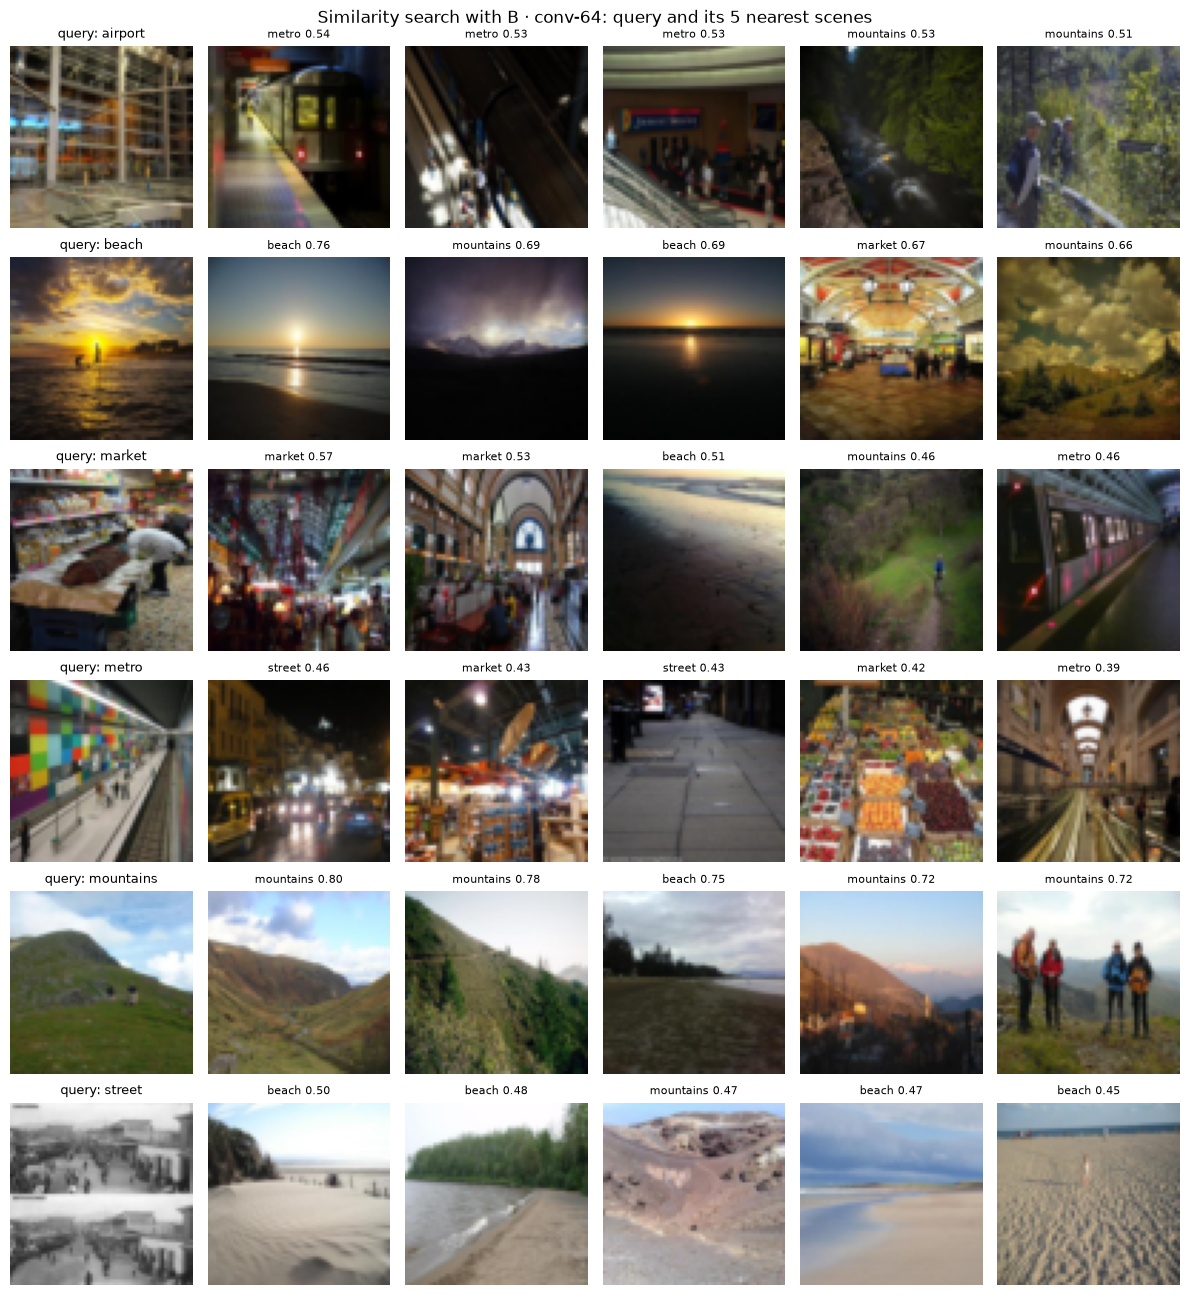

In [12]:
BEST = table.sort_values("place precision@5", ascending=False)["setup"].iloc[0]
Z = Zs[BEST]; print("best for the use:", BEST)
qs = lib.loc[queries].groupby("place").sample(1, random_state=SEED).index
fig, axs = plt.subplots(len(qs), 6, figsize=(12, 2.2 * len(qs)))
for row, q in zip(axs, qs):
    s = Z @ Z[q]; s[q] = -9; nn_ = np.argsort(-s)[:5]
    row[0].imshow(X_all[lib.loc[q, "i"]]); row[0].set_title(f"query: {lib.loc[q, 'place']}", fontsize=9)
    for ax, n in zip(row[1:], nn_):
        ax.imshow(X_all[lib.loc[n, "i"]]); ax.set_title(f"{lib.loc[n, 'place']} {s[n]:.2f}", fontsize=8)
    for ax in row: ax.axis("off")
plt.suptitle(f"Similarity search with {BEST}: query and its 5 nearest scenes"); plt.tight_layout()
plt.savefig(FIG / "04_similarity.png", dpi=110); plt.show()

C:\Users\dell\hackathon-team8-chroma\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\dell\hackathon-team8-chroma\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


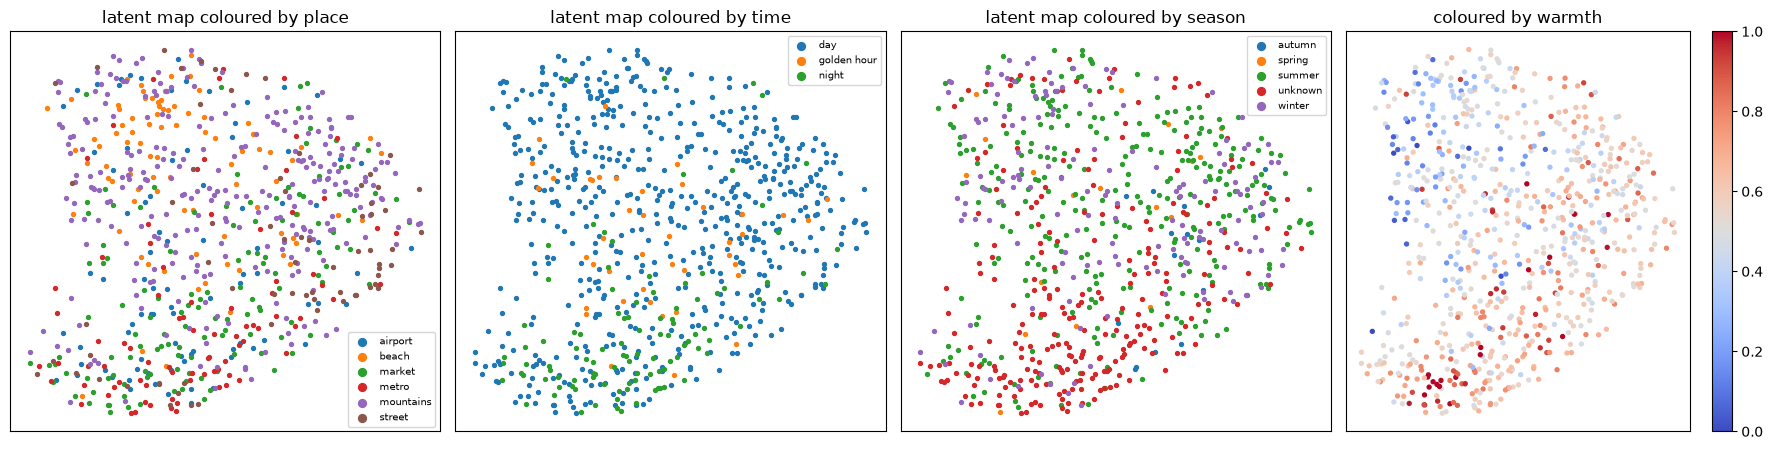

In [13]:
import umap
emb = umap.UMAP(n_neighbors=20, min_dist=0.2, random_state=SEED).fit_transform(Z)
fig, axs = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, col in zip(axs[:3], ["place", "time", "season"]):
    for v in sorted(lib[col].unique()):
        sel = lib[col] == v; ax.scatter(emb[sel, 0], emb[sel, 1], s=8, label=v)
    ax.set_title(f"latent map coloured by {col}"); ax.legend(fontsize=7, markerscale=2); ax.set_xticks([]); ax.set_yticks([])
sc = axs[3].scatter(emb[:, 0], emb[:, 1], s=8, c=lib["warmth"], cmap="coolwarm"); axs[3].set_title("coloured by warmth")
axs[3].set_xticks([]); axs[3].set_yticks([]); plt.colorbar(sc, ax=axs[3])
plt.tight_layout(); plt.savefig(FIG / "05_latent_map.png", dpi=110); plt.show()

## 5. The model for the server (ONNX)

The exported model takes a batch of photos `(N, 3, 64, 64)`, pixels 0–1, and returns **two outputs**: the
reconstruction and the normalised latent vector. The server compares the latent vector with the library.

In [14]:
class Export(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x):
        z = self.m.encode(x)
        return self.m(x), z / z.norm(dim=1, keepdim=True)

best = models[BEST].eval()
wrapper = Export(best).eval()       # eval on the wrapper too: export restores the wrapper's mode afterwards
onnx_path = MODELS / "chroma_ae.onnx"
torch.onnx.export(wrapper, Xte[:1], onnx_path, input_names=["image"], output_names=["reconstruction", "latent"],
                  dynamic_axes={"image": {0: "n"}, "reconstruction": {0: "n"}, "latent": {0: "n"}}, opset_version=17, dynamo=False)
(APP / "chroma_ae.onnx").write_bytes(onnx_path.read_bytes())
print(onnx_path, round(onnx_path.stat().st_size / 1e6, 2), "MB")

C:\Users\dell\AppData\Local\Temp\ipykernel_51668\2732522674.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(wrapper, Xte[:1], onnx_path, input_names=["image"], output_names=["reconstruction", "latent"],


..\models\chroma_ae.onnx 7.64 MB


In [15]:
import onnxruntime as ort
sess = ort.InferenceSession(str(onnx_path))
x = Xte[:16]
rec_onnx, z_onnx = sess.run(None, {"image": x.numpy()})
wrapper.eval()
with torch.no_grad(): rec_pt, z_pt = wrapper(x)
print("max difference, reconstruction:", float(np.abs(rec_onnx - rec_pt.numpy()).max()))
print("max difference, latent:        ", float(np.abs(z_onnx - z_pt.numpy()).max()))
assert np.allclose(rec_onnx, rec_pt.numpy(), atol=1e-4) and np.allclose(z_onnx, z_pt.numpy(), atol=1e-4)
print("ONNX gives the same results as PyTorch.")

max difference, reconstruction: 6.556510925292969e-07
max difference, latent:         1.1920928955078125e-07
ONNX gives the same results as PyTorch.


In [16]:
# The library the server searches: latent vectors + labels (no photos: Places365 photos are not republished).
cols = ["name", "place", "time", "season", "brightness", "saturation", "contrast", "warmth", "n_colours",
        "palette", "scale", "chords", "sevenths", "melody", "drums"]
lib[cols].to_csv(APP / "library.csv", index=False)
np.save(APP / "library_latent.npy", Z.astype(np.float32))
config = {
    "architecture": BEST, "latent_dim": int(Z.shape[1]), "image_size": SIZE,
    "preprocessing": "RGB, resized to 64x64 (bilinear), pixels scaled to 0-1, shape (N, 3, 64, 64)",
    "outputs": {"reconstruction": "(N, 3, 64, 64)", "latent": "(N, latent_dim), L2-normalised"},
    "use": "similarity search: cosine similarity between the latent of a photo and library_latent.npy",
    "library": "library.csv (labels, colours and music parameters of 731 Places365 scenes)",
    "place_precision_at_5": float(table.loc[table.setup == BEST, "place precision@5"].iloc[0]),
    "chance_precision": round(float(chance), 3),
    "seed": SEED,
}
(APP / "chroma_ae_config.json").write_text(json.dumps(config, indent=2))
config

{'architecture': 'B · conv-64',
 'latent_dim': 64,
 'image_size': 64,
 'preprocessing': 'RGB, resized to 64x64 (bilinear), pixels scaled to 0-1, shape (N, 3, 64, 64)',
 'outputs': {'reconstruction': '(N, 3, 64, 64)',
  'latent': '(N, latent_dim), L2-normalised'},
 'use': 'similarity search: cosine similarity between the latent of a photo and library_latent.npy',
 'library': 'library.csv (labels, colours and music parameters of 731 Places365 scenes)',
 'place_precision_at_5': 0.352,
 'chance_precision': 0.218,
 'seed': 8}

## 6. Conclusions

- **Chosen model: B · conv-64.** Best similarity search (place precision@5 = 0.352, chance = 0.218, 1.6 ×), smallest convolutional model (1.9 M parameters, 7.6 MB ONNX, fits Render's free plan), 64 numbers per photo.
- **What the latent space encodes: light and setting.** The latent map (figure 5) runs from bright outdoor scenes (beach, mountains, day) at the top to indoor and night scenes (metro, airport, market, warm light) at the bottom; warmth changes smoothly across it. A sunset at the beach finds other sunsets, including one over mountains (figure 4).
- **For Chroma this is useful:** the music is driven by light and colour, so "photos that look alike" is the right neighbourhood. The *place* label itself comes from CLIP, not from the autoencoder.
- **Limits.** 0.35 means most neighbours are still another place; old black-and-white photos land next to pale beaches (figure 4, last row). Places365 is not Barcelona: the Barcelona photos (Wikimedia, our own) are added to the library next.
- **ONNX** gives the same results as PyTorch (max difference 7 × 10⁻⁷). The server needs `model_app/`: the ONNX file, the config and the library.